<a href="https://colab.research.google.com/github/limenez/deteccao-fraude-cartao/blob/main/deteccao_fraude_cartao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de fraude em cartão de crédito.





In [2]:
import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.shape

(284807, 31)

In [4]:
df['Class'].value_counts()

,count
Class,
0,284315
1,492


In [5]:
df['Class'].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Variável nova: log do valor da compra
df['log_amount'] = np.log1p(df['Amount'])

# 2. Separar X (informações) e y (fraude ou não)
X = df.drop(columns=['Class', 'Amount'])
y = df['Class']

# 3. Separar treino e teste mantendo a proporção de fraudes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Padronizar Time e log_amount (aprende só no treino)
colunas = ['Time', 'log_amount']
scaler = StandardScaler()
X_train[colunas] = scaler.fit_transform(X_train[colunas])
X_test[colunas] = scaler.transform(X_test[colunas])

# 5. Conferir se a proporção de fraude ficou igual nos dois
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64
Class
0    99.827955
1     0.172045
Name: proportion, dtype: float64


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

modelo_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
modelo_lr.fit(X_train, y_train)

y_pred = modelo_lr.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))


              precision    recall  f1-score   support

           0      1.000     0.975     0.987     56864
           1      0.060     0.918     0.113        98

    accuracy                          0.975     56962
   macro avg      0.530     0.947     0.550     56962
weighted avg      0.998     0.975     0.986     56962



In [8]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42
)
modelo_rf.fit(X_train, y_train)

y_pred_rf = modelo_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf, digits=3))


              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56864
           1      0.961     0.745     0.839        98

    accuracy                          1.000     56962
   macro avg      0.980     0.872     0.919     56962
weighted avg      0.999     1.000     0.999     56962



In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

# probabilidade de fraude para cada compra do teste
probs_rf = modelo_rf.predict_proba(X_test)[:, 1]

for limiar in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (probs_rf >= limiar).astype(int)
    print(
        f"limiar {limiar}: "
        f"recall={recall_score(y_test, pred):.3f}  "
        f"precisão={precision_score(y_test, pred):.3f}  "
        f"f1={f1_score(y_test, pred):.3f}"
    )


limiar 0.5: recall=0.745  precisão=0.961  f1=0.839
limiar 0.4: recall=0.806  precisão=0.952  f1=0.873
limiar 0.3: recall=0.847  precisão=0.922  f1=0.883
limiar 0.2: recall=0.857  precisão=0.857  f1=0.857
limiar 0.1: recall=0.878  precisão=0.741  f1=0.804


In [10]:
from xgboost import XGBClassifier

peso = (y_train == 0).sum() / (y_train == 1).sum()

modelo_xgb = XGBClassifier(
    n_estimators=200, scale_pos_weight=peso,
    eval_metric='logloss', n_jobs=-1, random_state=42
)
modelo_xgb.fit(X_train, y_train)

probs_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

for limiar in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred = (probs_xgb >= limiar).astype(int)
    print(
        f"limiar {limiar}: "
        f"recall={recall_score(y_test, pred):.3f}  "
        f"precisão={precision_score(y_test, pred):.3f}  "
        f"f1={f1_score(y_test, pred):.3f}"
    )

limiar 0.5: recall=0.837  precisão=0.872  f1=0.854
limiar 0.4: recall=0.837  precisão=0.872  f1=0.854
limiar 0.3: recall=0.837  precisão=0.863  f1=0.850
limiar 0.2: recall=0.837  precisão=0.854  f1=0.845
limiar 0.1: recall=0.847  precisão=0.814  f1=0.830


,Modelo,Limiar,Recall,Precisão,F1,AUC-ROC,AUC-PR
0,Regressão logística,0.5,0.918,0.060,0.113,0.971,0.711
1,Random Forest,0.3,0.847,0.922,0.883,0.953,0.854
2,XGBoost,0.5,0.837,0.872,0.854,0.971,0.882


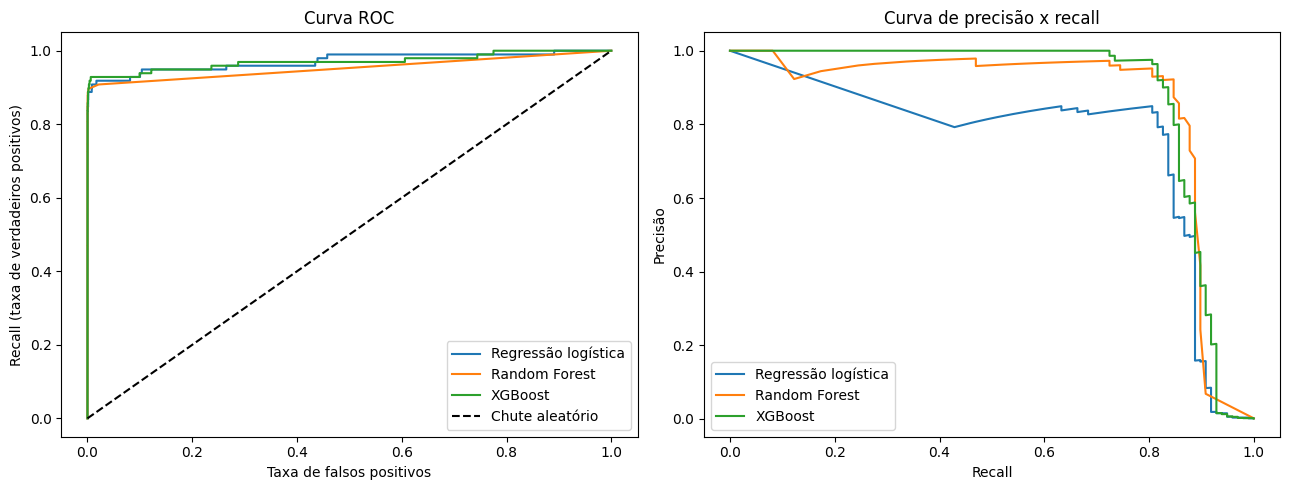

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

probs_lr = modelo_lr.predict_proba(X_test)[:, 1]

modelos = {
    'Regressão logística': (probs_lr, 0.5),
    'Random Forest': (probs_rf, 0.3),
    'XGBoost': (probs_xgb, 0.5),
}

# Tabela final
linhas = []
for nome, (probs, limiar) in modelos.items():
    pred = (probs >= limiar).astype(int)
    linhas.append({
        'Modelo': nome,
        'Limiar': limiar,
        'Recall': recall_score(y_test, pred),
        'Precisão': precision_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC-ROC': roc_auc_score(y_test, probs),
        'AUC-PR': average_precision_score(y_test, probs),
    })
tabela = pd.DataFrame(linhas).round(3)
display(tabela)

# Curvas
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nome, (probs, _) in modelos.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax[0].plot(fpr, tpr, label=nome)
    prec, rec, _ = precision_recall_curve(y_test, probs)
    ax[1].plot(rec, prec, label=nome)

ax[0].plot([0, 1], [0, 1], 'k--', label='Chute aleatório')
ax[0].set_title('Curva ROC')
ax[0].set_xlabel('Taxa de falsos positivos')
ax[0].set_ylabel('Recall (taxa de verdadeiros positivos)')
ax[0].legend()

ax[1].set_title('Curva de precisão x recall')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precisão')
ax[1].legend()

plt.tight_layout()
plt.show()

In [13]:
!pip install shap -q

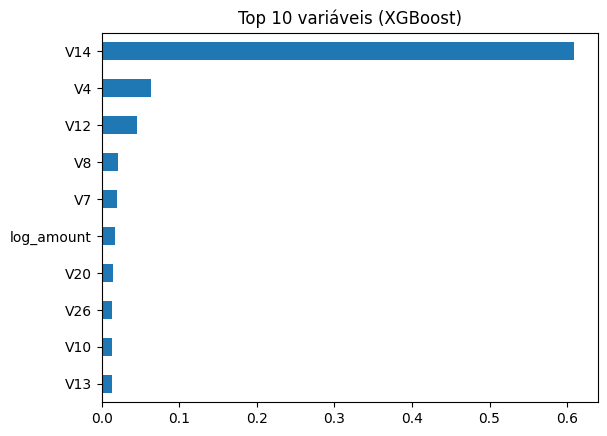

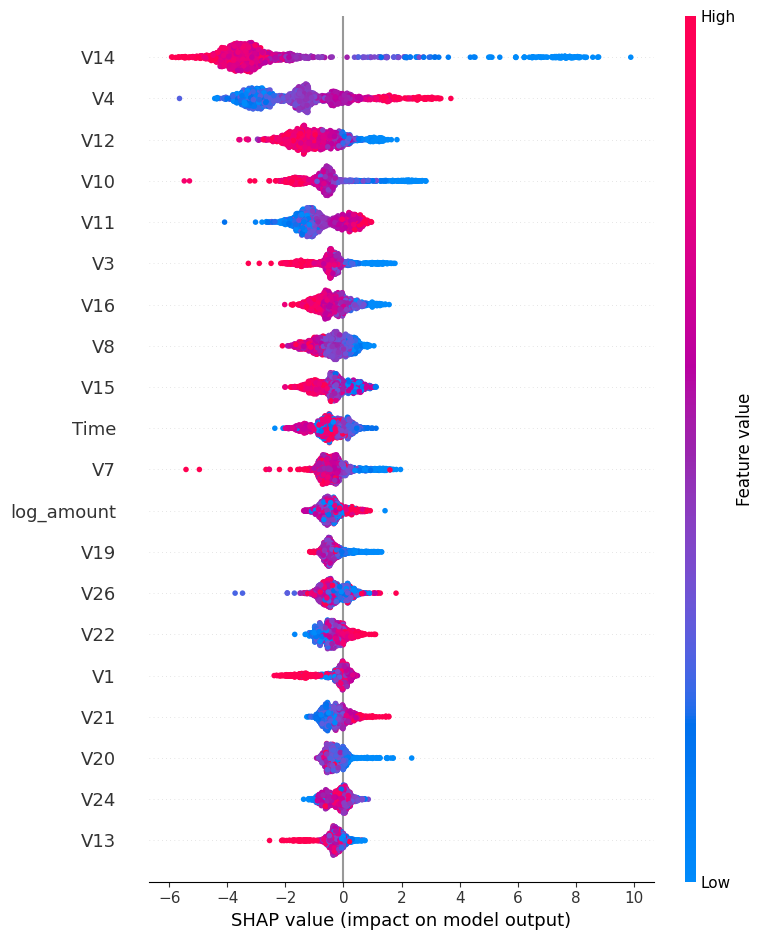

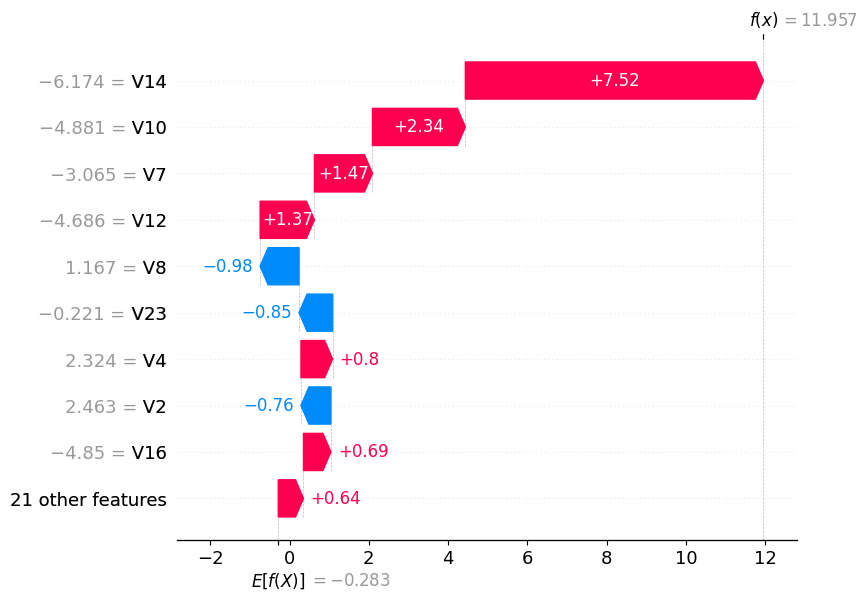

In [14]:
import shap

# Importância simples das variáveis (top 10)
importancias = pd.Series(modelo_xgb.feature_importances_, index=X_train.columns)
importancias.sort_values(ascending=False).head(10).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 10 variáveis (XGBoost)')
plt.show()

# Amostra com todas as fraudes do teste + 1500 compras normais
amostra = pd.concat([
    X_test[y_test == 1],
    X_test[y_test == 0].sample(1500, random_state=42),
])

explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer.shap_values(amostra)

# Visão geral: quais variáveis mais pesam nas decisões
shap.summary_plot(shap_values, amostra)

# Uma fraude específica: por que ela foi marcada?
fraudes_detectadas = X_test[(y_test == 1) & (probs_xgb >= 0.5)]
exemplo = fraudes_detectadas.iloc[[0]]
shap.plots.waterfall(explainer(exemplo)[0])